# Variational Autoencoder (VAE): a simple implementation

**Goal:** build a VAE from scratch on MNIST digits, in plain language, and see it generate new digits.

### The idea in one picture

```
image (28x28) --> ENCODER --> mu, logvar --> sample z --> DECODER --> rebuilt image
                                  (a small "cloud" of points, not one point)
```

- A normal **autoencoder** squeezes an image into a few numbers (a code), then rebuilds it. Good at copying, bad at making new images: random codes decode to garbage.
- A **VAE** makes the encoder output a *range* (a Gaussian with mean `mu` and spread `sigma`) instead of one point. Then it pushes all those ranges to look like a standard normal `N(0, 1)`.
- Result: the code space is smooth and filled in. Pick any random `z ~ N(0, 1)`, decode it, and you get a real-looking digit.

### Three key pieces
1. **Encoder:** image -> `mu` and `logvar` (log of variance; easier to learn than variance, always valid).
2. **Reparameterization trick:** `z = mu + sigma * eps`, with `eps ~ N(0, 1)`. Randomness sits in `eps`, so gradients can still flow through `mu` and `sigma`.
3. **Loss = reconstruction + KL:**
   - *Reconstruction:* how close the rebuilt image is to the input.
   - *KL divergence:* how far each encoder Gaussian is from `N(0, 1)`. Keeps the code space tidy.

## 1. Setup

In [15]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import time
import os
import matplotlib.pyplot as plt
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

torch.manual_seed(0)
device = torch.device("cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu")
print(f"Using device: {device}")
os.makedirs("../outputs", exist_ok=True)

Using device: mps


## 2. Data

MNIST: 28x28 grayscale digits. `ToTensor()` scales pixels to `[0, 1]`, which matches the decoder's sigmoid output.

In [16]:
transform = transforms.ToTensor()
train_ds = datasets.MNIST("../data", train=True, download=True, transform=transform)
test_ds = datasets.MNIST("../data", train=False, download=True, transform=transform)

train_loader = DataLoader(train_ds, batch_size=128, shuffle=True)
test_loader = DataLoader(test_ds, batch_size=128)
print(len(train_ds), "train images,", len(test_ds), "test images")

100%|██████████| 9.91M/9.91M [00:05<00:00, 1.71MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 85.3kB/s]
100%|██████████| 1.65M/1.65M [00:04<00:00, 390kB/s] 
100%|██████████| 4.54k/4.54k [00:00<00:00, 1.18MB/s]

60000 train images, 10000 test images


## 3. The model

Kept tiny on purpose: plain fully connected layers.

- **Encoder:** 784 -> 400 -> two heads: `mu` (size `latent_dim`) and `logvar` (size `latent_dim`).
- **Decoder:** `latent_dim` -> 400 -> 784, sigmoid so pixels land in `[0, 1]`.
- `latent_dim = 2` so we can plot the code space directly. Use 16-32 for sharper images.

In [17]:
class VAE(nn.Module):
    def __init__(self, input_dim=784, hidden_dim=400, latent_dim=2):
        super().__init__()
        # Encoder: image -> hidden -> (mu, logvar)
        self.enc = nn.Linear(input_dim, hidden_dim)
        self.mu_head = nn.Linear(hidden_dim, latent_dim)
        self.logvar_head = nn.Linear(hidden_dim, latent_dim)
        # Decoder: z -> hidden -> image
        self.dec1 = nn.Linear(latent_dim, hidden_dim)
        self.dec2 = nn.Linear(hidden_dim, input_dim)

    def encode(self, x):
        h = F.relu(self.enc(x))
        return self.mu_head(h), self.logvar_head(h)

    def reparameterize(self, mu, logvar):
        # z = mu + sigma * eps. The randomness lives in eps, so mu and logvar still get gradients.
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + std * eps

    def decode(self, z):
        h = F.relu(self.dec1(z))
        return torch.sigmoid(self.dec2(h))

    def forward(self, x):
        x = x.view(x.size(0), -1)          # flatten 28x28 -> 784
        mu, logvar = self.encode(x)
        z = self.reparameterize(mu, logvar)
        return self.decode(z), mu, logvar


model = VAE().to(device)
print(model)
print("Parameters:", sum(p.numel() for p in model.parameters()))

VAE(
  (enc): Linear(in_features=784, out_features=400, bias=True)
  (mu_head): Linear(in_features=400, out_features=2, bias=True)
  (logvar_head): Linear(in_features=400, out_features=2, bias=True)
  (dec1): Linear(in_features=2, out_features=400, bias=True)
  (dec2): Linear(in_features=400, out_features=784, bias=True)
)
Parameters: 631188


## 4. The loss

$$\text{loss} = \underbrace{\text{BCE}(\hat{x}, x)}_{\text{rebuild well}} + \underbrace{-\tfrac{1}{2}\sum\left(1 + \log\sigma^2 - \mu^2 - \sigma^2\right)}_{\text{KL: stay close to } N(0,1)}$$

- **BCE** (binary cross-entropy) works because pixels are in `[0, 1]`. Summed over pixels.
- **KL** has a closed form for two Gaussians. It is zero only when `mu = 0` and `sigma = 1`.
- The two terms pull against each other: reconstruction wants distinct, precise codes; KL wants every code to look like `N(0, 1)`. The balance gives a smooth, usable latent space.

In [18]:
def vae_loss(recon, x, mu, logvar):
    x = x.view(x.size(0), -1)
    recon_loss = F.binary_cross_entropy(recon, x, reduction="sum")
    kl = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return recon_loss + kl, recon_loss, kl

## 5. Train

In [19]:
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
epochs = 10
history = {"loss": [], "recon": [], "kl": [], "test": []}
start = time.time()

for epoch in range(1, epochs + 1):
    model.train()
    total, total_rec, total_kl = 0.0, 0.0, 0.0
    for x, _ in train_loader:
        x = x.to(device)
        recon, mu, logvar = model(x)
        loss, rec, kl = vae_loss(recon, x, mu, logvar)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total += loss.item(); total_rec += rec.item(); total_kl += kl.item()

    # Test loss: same formula, no gradients
    model.eval()
    test_total = 0.0
    with torch.no_grad():
        for x, _ in test_loader:
            x = x.to(device)
            recon, mu, logvar = model(x)
            test_total += vae_loss(recon, x, mu, logvar)[0].item()

    n = len(train_ds)
    history["loss"].append(total / n); history["recon"].append(total_rec / n)
    history["kl"].append(total_kl / n); history["test"].append(test_total / len(test_ds))
    print(f"Epoch {epoch:2d} | loss {total/n:.1f} | recon {total_rec/n:.1f} | KL {total_kl/n:.2f} | test {test_total/len(test_ds):.1f}")

print(f"Training took {time.time() - start:.0f}s on {device}")

Epoch  1 | loss 189.2 | recon 183.4 | KL 5.82 | test 170.8
Epoch  2 | loss 167.5 | recon 162.1 | KL 5.37 | test 164.3
Epoch  3 | loss 163.1 | recon 157.6 | KL 5.45 | test 161.3
Epoch  4 | loss 160.7 | recon 155.1 | KL 5.58 | test 159.1
Epoch  5 | loss 158.9 | recon 153.3 | KL 5.65 | test 158.1
Epoch  6 | loss 157.5 | recon 151.8 | KL 5.73 | test 156.6
Epoch  7 | loss 156.4 | recon 150.6 | KL 5.77 | test 156.0
Epoch  8 | loss 155.4 | recon 149.6 | KL 5.81 | test 155.2
Epoch  9 | loss 154.6 | recon 148.8 | KL 5.83 | test 154.6
Epoch 10 | loss 154.0 | recon 148.2 | KL 5.85 | test 154.2
Training took 45s on mps


### Loss curves

Left: total loss for train and test. Right: the two parts of the train loss. Watch the KL go *up* early: the encoder learns to use its latent code, and that costs KL.

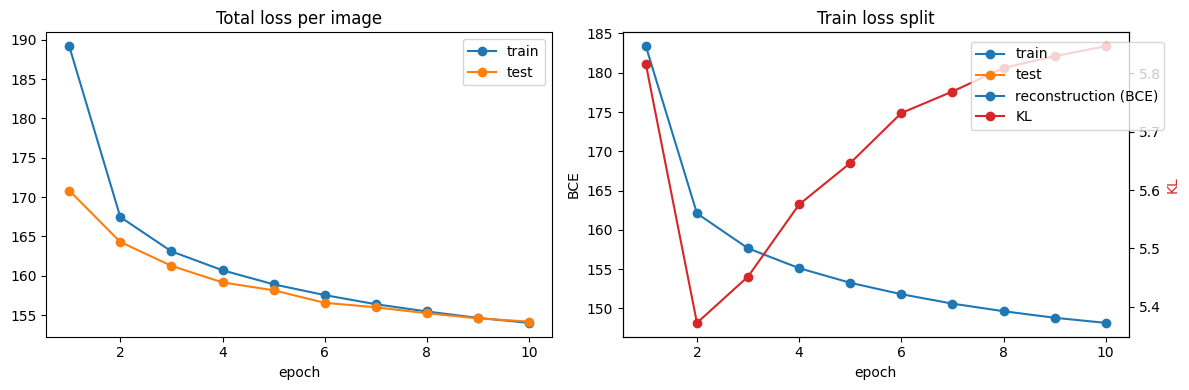

In [21]:
ep = range(1, epochs + 1)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.plot(ep, history["loss"], "o-", label="train")
ax1.plot(ep, history["test"], "o-", label="test")
ax1.set_title("Total loss per image"); ax1.set_xlabel("epoch"); ax1.legend()
ax2.plot(ep, history["recon"], "o-", label="reconstruction (BCE)")
ax2b = ax2.twinx()
ax2b.plot(ep, history["kl"], "o-", color="tab:red", label="KL")
ax2.set_title("Train loss split"); ax2.set_xlabel("epoch")
ax2.set_ylabel("BCE"); ax2b.set_ylabel("KL", color="tab:red")
fig.legend(loc="upper right", bbox_to_anchor=(0.98, 0.9))
plt.tight_layout(); plt.savefig("../outputs/vae_training.png", dpi=120, bbox_inches="tight"); plt.show()

## 6. Reconstructions

Top row: real test digits. Bottom row: what the VAE rebuilds from its 2-number code. A bit blurry: that is normal for a VAE with only 2 latent dims.

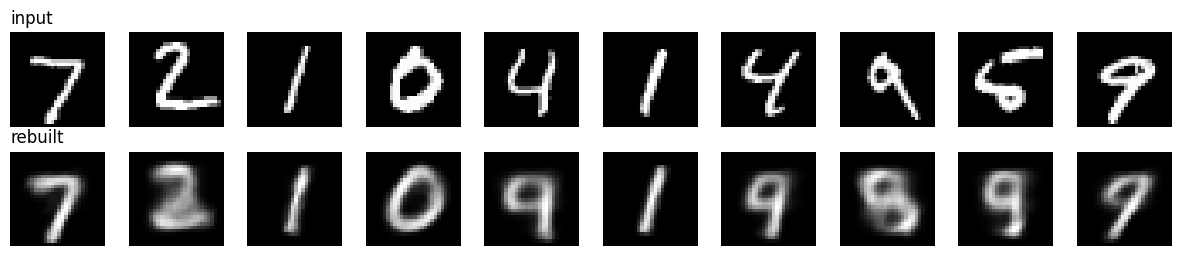

In [22]:
model.eval()
x, _ = next(iter(test_loader))
x = x[:10].to(device)
with torch.no_grad():
    recon, _, _ = model(x)

fig, axes = plt.subplots(2, 10, figsize=(12, 2.6))
for i in range(10):
    axes[0, i].imshow(x[i].cpu().squeeze(), cmap="gray")
    axes[1, i].imshow(recon[i].cpu().view(28, 28), cmap="gray")
    axes[0, i].axis("off"); axes[1, i].axis("off")
axes[0, 0].set_title("input", loc="left"); axes[1, 0].set_title("rebuilt", loc="left")
plt.tight_layout(); plt.savefig("../outputs/vae_reconstructions.png", dpi=120, bbox_inches="tight"); plt.show()

## 7. Generate new digits

This is what makes a VAE generative. No input image: sample `z ~ N(0, 1)` and decode.

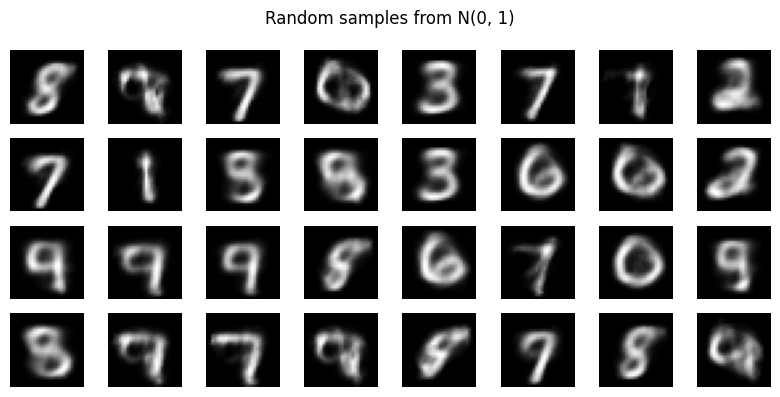

In [23]:
with torch.no_grad():
    z = torch.randn(32, 2, device=device)
    samples = model.decode(z).cpu().view(-1, 28, 28)

fig, axes = plt.subplots(4, 8, figsize=(8, 4))
for ax, img in zip(axes.flat, samples):
    ax.imshow(img, cmap="gray"); ax.axis("off")
plt.suptitle("Random samples from N(0, 1)"); plt.tight_layout()
plt.savefig("../outputs/vae_samples.png", dpi=120, bbox_inches="tight"); plt.show()

## 8. Look at the latent space

With `latent_dim = 2` we can see the code space directly.

- **Left:** each test image's `mu`, colored by its true digit. The model never saw labels, yet digits form clusters.
- **Right:** walk a grid of `z` values and decode each one. Digits morph smoothly into each other: no holes, no garbage. That smoothness is the whole point of the KL term.

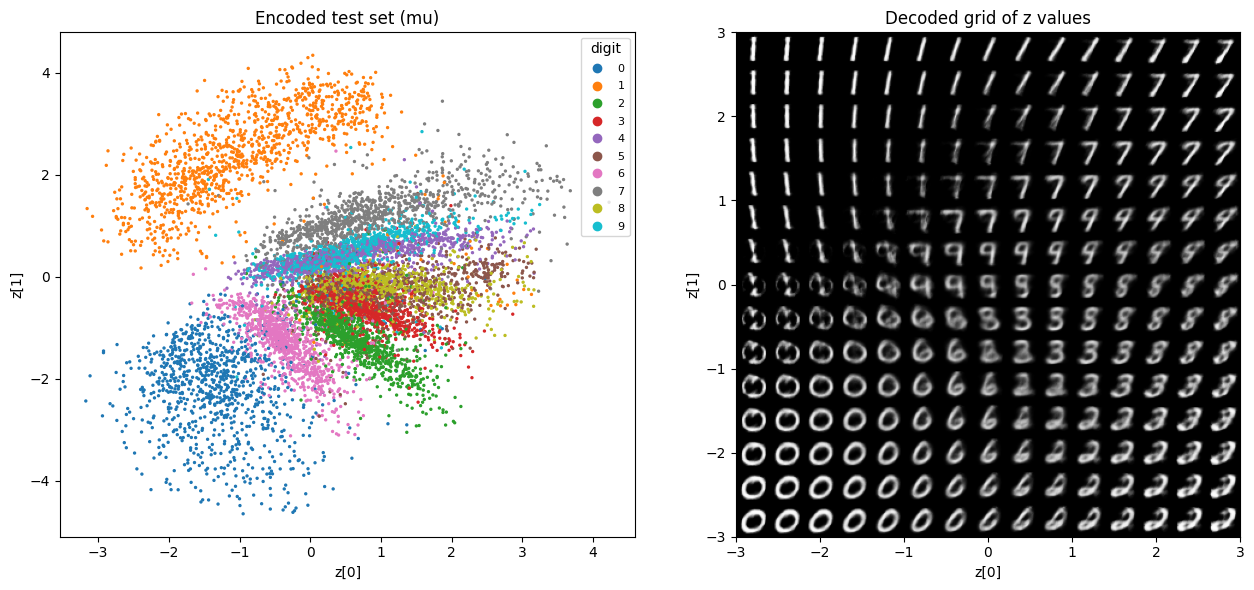

In [24]:
mus, labels = [], []
with torch.no_grad():
    for x, y in test_loader:
        mu, _ = model.encode(x.to(device).view(x.size(0), -1))
        mus.append(mu.cpu()); labels.append(y)
mus, labels = torch.cat(mus), torch.cat(labels)

# Grid of z values from -3 to 3 in both dims
n = 15
grid = torch.linspace(-3, 3, n)
canvas = torch.zeros(n * 28, n * 28)
with torch.no_grad():
    for i, yv in enumerate(grid.flip(0)):
        for j, xv in enumerate(grid):
            img = model.decode(torch.tensor([[xv, yv]], device=device)).cpu().view(28, 28)
            canvas[i*28:(i+1)*28, j*28:(j+1)*28] = img

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6))
sc = ax1.scatter(mus[:, 0], mus[:, 1], c=labels, cmap="tab10", s=2)
ax1.legend(*sc.legend_elements(), title="digit", loc="upper right", fontsize=8)
ax1.set_title("Encoded test set (mu)"); ax1.set_xlabel("z[0]"); ax1.set_ylabel("z[1]")
ax2.imshow(canvas, cmap="gray", extent=[-3, 3, -3, 3])
ax2.set_title("Decoded grid of z values"); ax2.set_xlabel("z[0]"); ax2.set_ylabel("z[1]")
plt.tight_layout(); plt.savefig("../outputs/vae_latent_space.png", dpi=120, bbox_inches="tight"); plt.show()

## 9. Walk from one digit to another

Encode two real digits, draw a straight line between their codes, and decode points along the line. Every step in between is still a believable digit.

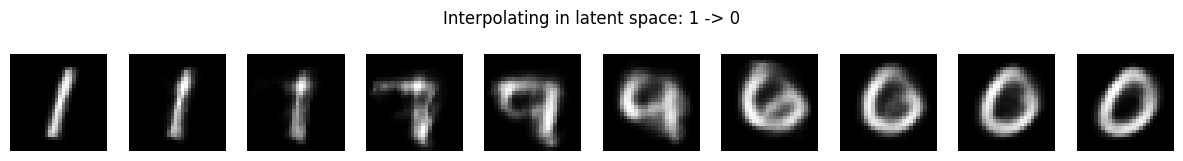

In [25]:
x, y = next(iter(test_loader))
a = x[(y == 1).nonzero()[0]].to(device)   # first "1" in the batch
b = x[(y == 0).nonzero()[0]].to(device)   # first "0" in the batch
with torch.no_grad():
    mu_a, _ = model.encode(a.view(1, -1))
    mu_b, _ = model.encode(b.view(1, -1))
    steps = torch.linspace(0, 1, 10, device=device).unsqueeze(1)
    path = (1 - steps) * mu_a + steps * mu_b
    imgs = model.decode(path).cpu().view(-1, 28, 28)

fig, axes = plt.subplots(1, 10, figsize=(12, 1.6))
for ax, img in zip(axes, imgs):
    ax.imshow(img, cmap="gray"); ax.axis("off")
plt.suptitle("Interpolating in latent space: 1 -> 0"); plt.tight_layout()
plt.savefig("../outputs/vae_interpolation.png", dpi=120, bbox_inches="tight"); plt.show()

## 10. Recap

| Piece | What it does | Why |
|---|---|---|
| Encoder -> `mu`, `logvar` | Maps an image to a Gaussian, not a point | Makes the code space continuous |
| Reparameterization `z = mu + sigma * eps` | Samples while keeping gradients | Lets backprop train the encoder |
| Reconstruction loss (BCE) | Rebuilt image should match input | Keeps codes informative |
| KL loss | Pushes each Gaussian toward `N(0, 1)` | Lets us sample new images from `N(0, 1)` |
| Decoder | Code -> image | Used for both rebuilding and generating |

**Next steps to try**
- Raise `latent_dim` to 16 or 32: sharper reconstructions (but no 2D plot).
- Swap the linear layers for conv layers (a conv VAE) on a harder dataset like FashionMNIST or CelebA.
- **beta-VAE:** multiply the KL term by `beta > 1` for more disentangled codes, `beta < 1` for sharper images.
- VAEs are the "compress to latent" stage of **Stable Diffusion**: diffusion runs in a VAE's latent space, not on pixels.